# Frozen Whisper on the final fusion dataset

Does the acoustic branch improve on a strong frozen Whisper control?

Use the **same 40,000 clips and speaker splits** as the 24 October 2026 final fusion experiment.
The encoder is frozen `openai/whisper-base.en`. Only the SVM heads learn class labels.
This is supervised classification of frozen features. It is not a zero-shot Whisper test.

Test two controls: all **512 Whisper features**, and **32 PCA components** as used in fusion.
Compare each with the saved Acoustic65 SVM and the uncalibrated Fusion SVM.
Keep this run separate from the earlier 2,000-clip experiment.

**Flow:** verify the data → verify frozen features → select C on validation → check speaker folds → refit on development → evaluate the fixed test set.


## 1. Set the local paths

Use the **Singlish final fusion (Python 3.14)** kernel.
This environment matches the saved models. Do not install packages in this notebook.

The audio already has the final preparation: mono, 16 kHz, 3–6 seconds, RMS normalization and a peak limit.
Read the FLAC audio in the Parquet shards. Do not trim or normalize it again.

The default reuses the exact original fusion embeddings after all audio hashes match.
Set `rebuild_whisper` to `True` to run the pinned encoder again. This takes more time.
Both modes keep the encoder weights fixed.


In [1]:
from pathlib import Path
import os
import sys
for key in ['OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS', 'NUMEXPR_NUM_THREADS']:
    os.environ[key] = '4'
os.environ['USE_TF'] = '0'
%matplotlib inline
PROJECT_ROOT = Path('/home/mh/nusproj/singlish-whisper')
DATA_ROOT = PROJECT_ROOT / 'data/accent_dataset_3to6s_40k'
sys.path.insert(0, str(PROJECT_ROOT / 'notebooks'))
import frozen_whisper_40k as study
import pandas as pd
from IPython.display import display, Markdown
config = study.config(PROJECT_ROOT, DATA_ROOT)
config['rebuild_whisper'] = False
config['run_folds'] = True
print('Data:', DATA_ROOT)
print('Output:', config['output'])
print('Python:', sys.executable)


Data: /home/mh/nusproj/singlish-whisper/data/accent_dataset_3to6s_40k
Output: /home/mh/nusproj/singlish-whisper/outputs/frozen_whisper_40000_20261028
Python: /home/mh/miniconda3/envs/singlish-py314/bin/python


## 2. Keep the original clip list and speaker splits

Check the actual Parquet metadata against the fixed original manifest and the saved E1 split.
Stop if a clip ID, class label, speaker, or split differs.
A speaker must stay in one partition. No new random split is made.

Class 1 means Singapore. Class 0 means non-Singapore.
All class-1 clips come from MNSC. Class and recording source remain linked.


In [2]:
frame, split, split_summary = study.load_dataset(config)
display(split_summary)
display(frame.groupby(['source', 'label']).agg(clips=('clip_id', 'size'), speakers=('speaker_group', 'nunique')))


Metadata matches the final fusion data. Speaker overlap: 0.


,split,label,clips,speakers
0,test,0,3085,1267
1,test,1,3034,215
2,train,0,13848,5960
3,train,1,13949,979
4,validation,0,3067,1300
5,validation,1,3017,204


,,clips,speakers
source,label,,
common_voice,0,18871,8348
mnsc,1,20000,1398
speech_accent_archive,0,329,52
speechocean762,0,800,127


## 3. Decode and check all audio

Check all 40,000 decoded audio hashes against the original reference.
Check the sample rate, channel count, PCM type, duration and duplicate audio.
An audio mismatch or decoding error stops the run.

Different FLAC bytes can contain identical PCM audio. Cache reuse requires identical decoded audio.
The saved dataset audit also reports four boundary-trim warnings. This test does not change the audio to remove them.


In [3]:
audio_audit = study.audit_audio(config, frame)
display(pd.DataFrame([audio_audit]))


Audio audit: 250/40,000 decoded
Audio audit: 500/40,000 decoded
Audio audit: 750/40,000 decoded
Audio audit: 1,000/40,000 decoded
Audio audit: 1,250/40,000 decoded
Audio audit: 1,500/40,000 decoded
Audio audit: 1,750/40,000 decoded
Audio audit: 2,000/40,000 decoded
Audio audit: 2,250/40,000 decoded
Audio audit: 2,500/40,000 decoded
Audio audit: 2,750/40,000 decoded
Audio audit: 3,000/40,000 decoded
Audio audit: 3,250/40,000 decoded
Audio audit: 3,500/40,000 decoded
Audio audit: 3,750/40,000 decoded
Audio audit: 4,000/40,000 decoded
Audio audit: 4,250/40,000 decoded
Audio audit: 4,500/40,000 decoded
Audio audit: 4,750/40,000 decoded
Audio audit: 5,000/40,000 decoded
Audio audit: 5,250/40,000 decoded
Audio audit: 5,500/40,000 decoded
Audio audit: 5,750/40,000 decoded
Audio audit: 6,000/40,000 decoded
Audio audit: 6,250/40,000 decoded
Audio audit: 6,500/40,000 decoded
Audio audit: 6,750/40,000 decoded
Audio audit: 7,000/40,000 decoded
Audio audit: 7,250/40,000 decoded
Audio audit: 7,500/4

,status,clips_decoded,decoded_hash_matches,encoded_hash_matches_original_cache,duplicate_decoded_audio,seconds,reference_manifest_sha256,note
0,passed,40000,40000,40000,0,33.742558,87389b0aeb1ac273eff9e669f298b99bc3a73642ead135...,Decoded PCM matches the fixed original referen...


## 4. Load the matched frozen Whisper features

Use the pinned encoder revision from the final fusion run.
Each clip has 512 features. Mean pooling uses only encoder steps for real audio.
The padded tail of the 30-second input is excluded from the mean.

The cache must match the encoder, revision, pooling method, clip order, labels and speaker groups.
Cache reuse keeps the Whisper representation identical to the fusion representation.
It does not reuse any fitted Whisper-only SVM head.


In [4]:
X, whisper_provenance = study.load_whisper(config, frame)
display(pd.DataFrame([whisper_provenance]))


Whisper features: (40000, 512) | verified original fusion cache


,dataset_id,audio_id,model,revision,pooling,sample_rate,cache_id,resolved_revision,width,seconds,torch_version,transformers_version,reuse_mode,cache_path,cache_file_sha256,frozen,decoded_audio_matches_reference
0,899dd94a72cff7dc6536993ea0c91ce0aed927a8098305...,98341df1b3defc45d15c48ce926ebbe8da4734d93e52d7...,openai/whisper-base.en,main,mean_valid_encoder_frames_v1,16000,4fb592f4786ae83a4abeb3bc92a5c75ab3f178544f0358...,911407f4214e0e1d82085af863093ec0b66f9cd6,512,403.31813,2.14.0+cu130,4.57.6,verified original fusion cache,/home/mh/nusproj/E1_Feature_EngineeringV4/outp...,bccf31584fd0af0d2b248ef8182cef4145894e93b965e2...,True,True


## 5. Select C on validation speakers

Use an RBF SVM with balanced class weights and `gamma='scale'`.
Test C = 0.01, 0.1, 1, 10. This is the same C grid as the original fusion experiment.
Validation balanced accuracy selects C. Ties use macro F1, then the smaller C.

For full512: fit scaling, then the SVM.
For PCA32: fit scaling, PCA, component scaling, then the SVM.
Fit every learned step on training clips only. Do not use test clips to select settings.


In [5]:
selected_C, validation_trials = study.select_models(config, X, frame, split)
display(validation_trials)
print('Selected C:', selected_C)


Whisper full512 SVM C=0.01: validation BA 93.6042%; fit 200.7s
Whisper full512 SVM C=0.1: validation BA 97.2151%; fit 88.1s
Whisper full512 SVM C=1: validation BA 98.3926%; fit 43.2s
Whisper full512 SVM C=10: validation BA 98.7363%; fit 51.9s
Whisper PCA32 SVM C=0.01: validation BA 93.0355%; fit 43.0s
Whisper PCA32 SVM C=0.1: validation BA 94.2408%; fit 16.3s
Whisper PCA32 SVM C=1: validation BA 94.8619%; fit 9.6s
Whisper PCA32 SVM C=10: validation BA 94.5486%; fit 11.8s


,model,C,fit_seconds,accuracy,balanced_accuracy,macro_f1,roc_auc,sg_recall,non_sg_fpr,errors,false_positive,false_negative
0,Whisper full512 SVM,0.01,200.676169,0.935897,0.936042,0.935891,0.983116,0.953596,0.081513,390,250,140
1,Whisper full512 SVM,0.10,88.103603,0.972058,0.972151,0.972058,0.996821,0.983427,0.039126,170,120,50
2,Whisper full512 SVM,1.00,43.169894,0.983892,0.983926,0.983892,0.999100,0.988068,0.020215,98,62,36
3,Whisper full512 SVM,10.00,51.892042,0.987344,0.987363,0.987343,0.999327,0.989725,0.014998,77,46,31
4,Whisper PCA32 SVM,0.01,43.049519,0.930145,0.930355,0.930122,0.980303,0.955916,0.095207,425,292,133
5,Whisper PCA32 SVM,0.10,16.257272,0.942308,0.942408,0.942307,0.986262,0.954591,0.069775,351,214,137
6,Whisper PCA32 SVM,1.00,9.615760,0.948554,0.948619,0.948554,0.989123,0.956579,0.059341,313,182,131
7,Whisper PCA32 SVM,10.00,11.778345,0.945431,0.945486,0.945431,0.988157,0.952270,0.061298,332,188,144


Selected C: {'Whisper full512 SVM': 10.0, 'Whisper PCA32 SVM': 1.0}


## 6. Check three development speaker folds

Use the same three speaker folds as the final fusion study.
Refit all learned steps inside each fitting fold. Keep test speakers out.
Use the C already selected on the fixed validation set.

These are fixed-C stability checks. They are not nested model selection.
The fusion reference retains the original 65 selected acoustic features.
This notebook does not repeat acoustic feature selection inside each fold.


In [6]:
fold_scores = study.speaker_folds(config, X, frame, split, selected_C)
display(fold_scores)


Fold 1: Whisper full512 SVM BA=98.7515%
Fold 1: Whisper PCA32 SVM BA=95.4402%
Fold 2: Whisper full512 SVM BA=98.6893%
Fold 2: Whisper PCA32 SVM BA=94.8639%
Fold 3: Whisper full512 SVM BA=98.6714%
Fold 3: Whisper PCA32 SVM BA=95.2886%


,model,fold,seconds,accuracy,balanced_accuracy,macro_f1,roc_auc,sg_recall,non_sg_fpr,errors,false_positive,false_negative
0,Whisper full512 SVM,1,81.864848,0.987515,0.987515,0.987515,0.999086,0.987798,0.012768,141,72,69
1,Whisper PCA32 SVM,1,12.080413,0.954401,0.954402,0.954401,0.989113,0.953669,0.044866,515,253,262
2,Whisper full512 SVM,2,81.011475,0.986896,0.986893,0.986896,0.999193,0.988508,0.014722,148,83,65
3,Whisper PCA32 SVM,2,8.500260,0.948645,0.948639,0.948644,0.989828,0.952440,0.055161,580,311,269
4,Whisper full512 SVM,3,63.236980,0.986717,0.986714,0.986717,0.999208,0.988859,0.015431,150,87,63
5,Whisper PCA32 SVM,3,8.574452,0.952891,0.952886,0.952890,0.990795,0.956145,0.050372,532,284,248
6,Fusion SVM,1,NaN,0.988312,0.988312,0.988312,0.999356,0.988683,0.012059,132,68,64
7,Fusion SVM,2,NaN,0.985745,0.985735,0.985744,0.999038,0.991690,0.020220,161,114,47
8,Fusion SVM,3,NaN,0.984858,0.984853,0.984858,0.999034,0.987798,0.018092,171,102,69
9,SVM65,1,NaN,0.967593,0.967580,0.967590,0.994263,0.976835,0.041674,366,235,131


## 7. Refit and test once

Refit each selected pipeline on all 33,881 development clips: training plus validation.
Evaluate all 6,119 original test clips. Save each clip ID, speaker, label, prediction and decision score.
Use `predict()` for class labels. Decision scores are not calibrated probabilities.

Load the saved uncalibrated Acoustic65 and Fusion SVM predictions.
Check that all four models have the same test IDs, labels, sources and speakers.
The calibrated deployment model is a separate comparison.


In [7]:
test_predictions = study.final_test(config, X, frame, split, selected_C)
print('Test rows per model:')
display(test_predictions.groupby('model').size().to_frame('clips'))


Whisper full512 SVM test: {'accuracy': 0.9872528190880863, 'balanced_accuracy': 0.9872682798622633, 'macro_f1': 0.9872523012427138, 'roc_auc': 0.9990893055367104, 'sg_recall': 0.9891232696110744, 'non_sg_fpr': 0.014586709886547812, 'errors': 78, 'false_positive': 45, 'false_negative': 33}
Whisper PCA32 SVM test: {'accuracy': 0.9542408890341559, 'balanced_accuracy': 0.9542595051864926, 'macro_f1': 0.9542393918784509, 'roc_auc': 0.9895603473972451, 'sg_recall': 0.956493078444298, 'non_sg_fpr': 0.047974068071312805, 'errors': 280, 'false_positive': 148, 'false_negative': 132}
Test rows per model:


,clips
model,
Fusion SVM,6119
SVM65,6119
Whisper PCA32 SVM,6119
Whisper full512 SVM,6119


## 8. Measure performance and paired uncertainty

Balanced accuracy gives equal weight to recall for each class.
Macro F1 gives equal weight to the two class F1 scores.
ROC AUC measures score ranking. FP means non-Singapore predicted as Singapore.
FN means Singapore predicted as non-Singapore.

Resample whole test speakers 2,000 times within each class. Use the same draws for all models.
Report paired fusion-minus-Whisper differences. An interval that includes zero does not establish a gain.
The intervals describe this fitted model and split. They do not include training or selection uncertainty.


In [8]:
comparison, scores, paired = study.speaker_bootstrap(config, test_predictions)
display(comparison)
paired_rows = [dict(comparison=name, metric=metric, **value)
               for name, result in paired.items()
               for metric, value in result.items() if metric != 'errors']
display(pd.DataFrame(paired_rows))


,model,accuracy,balanced_accuracy,macro_f1,roc_auc,sg_recall,non_sg_fpr,errors,false_positive,false_negative,ba_ci95_low,ba_ci95_high,f1_ci95_low,f1_ci95_high
0,Whisper full512 SVM,0.987253,0.987268,0.987252,0.999089,0.989123,0.014587,78,45,33,0.982524,0.991576,0.982395,0.991557
1,Whisper PCA32 SVM,0.954241,0.954260,0.954239,0.989560,0.956493,0.047974,280,148,132,0.943014,0.964188,0.942770,0.964156
2,SVM65,0.966825,0.966930,0.966824,0.993857,0.979565,0.045705,203,141,62,0.959101,0.973950,0.959098,0.973944
3,Fusion SVM,0.986763,0.986820,0.986763,0.998970,0.993738,0.020097,81,62,19,0.982147,0.991080,0.981919,0.991155


,comparison,metric,difference,ci95
0,Fusion SVM minus Whisper full512 SVM,balanced_accuracy,-0.000448,"[-0.0050546881699446876, 0.004208502085632172]"
1,Fusion SVM minus Whisper full512 SVM,macro_f1,-0.000490,"[-0.005190608372410882, 0.004285484404871427]"
2,Fusion SVM minus Whisper PCA32 SVM,balanced_accuracy,0.032561,"[0.022933502495162416, 0.043527209662912965]"
3,Fusion SVM minus Whisper PCA32 SVM,macro_f1,0.032523,"[0.022817205236370992, 0.043527506939275755]"


## 9. Inspect the charts and source errors

Use source and accent groups to find where errors occur.
A source can have only one class. Its accuracy is a class recall, not a two-class balanced accuracy.
Small groups have less reliable estimates.


,model,category,group,clips,speakers,errors,accuracy,positive_class
0,Fusion SVM,source,common_voice,2913,1241,34,0.988328,False
1,Fusion SVM,source,mnsc,3034,215,19,0.993738,True
2,Fusion SVM,source,speech_accent_archive,50,8,4,0.920000,False
3,Fusion SVM,source,speechocean762,122,18,24,0.803279,False
4,SVM65,source,common_voice,2913,1241,72,0.975283,False
5,SVM65,source,mnsc,3034,215,62,0.979565,True
6,SVM65,source,speech_accent_archive,50,8,20,0.600000,False
7,SVM65,source,speechocean762,122,18,49,0.598361,False
8,Whisper PCA32 SVM,source,common_voice,2913,1241,96,0.967044,False
9,Whisper PCA32 SVM,source,mnsc,3034,215,132,0.956493,True


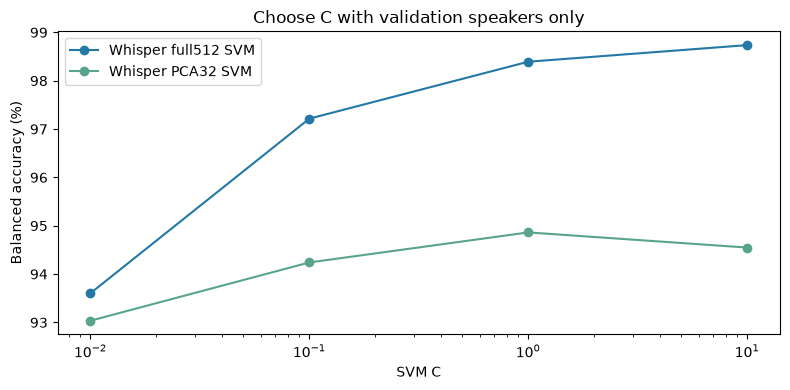

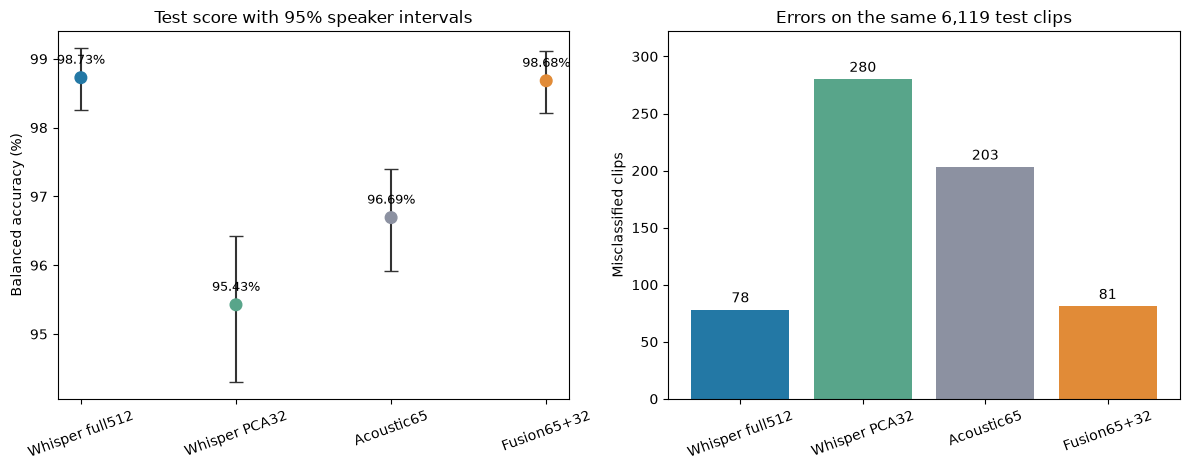

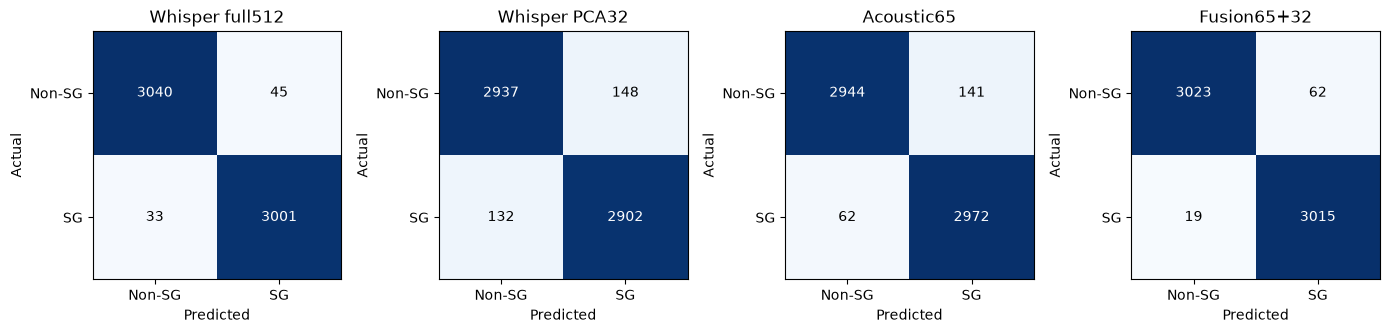

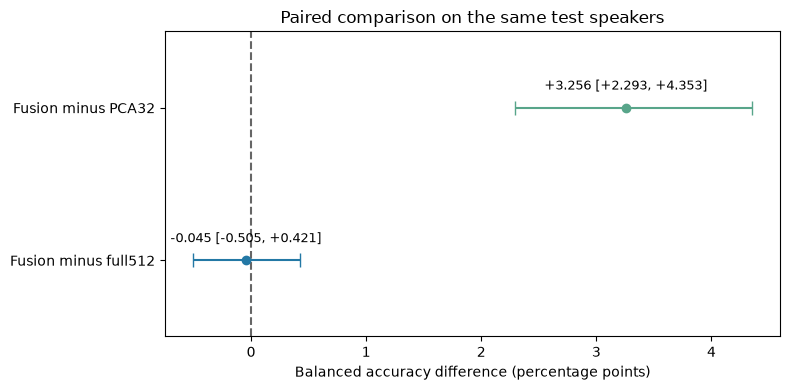

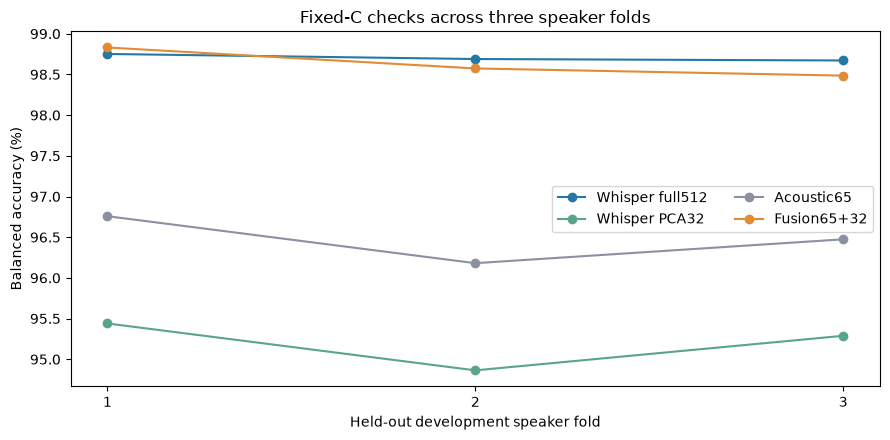

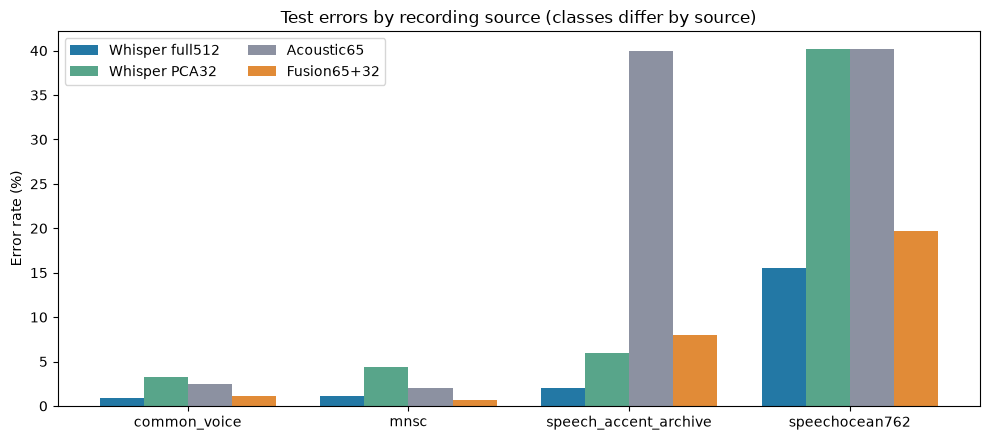

In [9]:
subgroups = study.subgroup_metrics(config, test_predictions)
display(subgroups)
study.charts(config, validation_trials, fold_scores, comparison, scores, paired, subgroups)


## 10. Record the measured conclusion

The test set was used in earlier experiments. This is a retrospective control on the original test set.
It is not a new untouched test set.
High scores on these sources do not establish accent recognition under new recording conditions.
A fusion gain does not prove that acoustic features add information independent of recording source.


In [10]:
interpretation = study.write_report(config, comparison, scores, paired, whisper_provenance, fold_scores)
display(Markdown('**Measured conclusion:** ' + interpretation))
print('Result summary:', PROJECT_ROOT / 'results/FROZEN_WHISPER_40000_20261028.md')
print('Saved predictions, models, audits and charts:', config['output'])


**Measured conclusion:** The paired interval includes zero. This test does not establish a fusion gain over full Whisper.

Result summary: /home/mh/nusproj/singlish-whisper/results/FROZEN_WHISPER_40000_20261028.md
Saved predictions, models, audits and charts: /home/mh/nusproj/singlish-whisper/outputs/frozen_whisper_40000_20261028
